# 07 · A virada de 2018: diagnóstico (exploratório, série E)

O `06_serie.ipynb` mostrou uma quebra por volta de 2018: o efeito do tamanho do município
sobre a variação do PT **mudou de sinal** (C5), a `% urbana` passou a favorecer o PT e o
efeito evangélico apareceu (C1). Antes de procurar **causas** (igrejas, internet móvel,
recessão, emendas: hipóteses E1–E6), este notebook pergunta **o que exatamente** mudou, só
com os dados que já temos:

1. A virada acontece no país todo ou em algumas regiões?
2. Sobrevive no 2º turno, quando é só o PT contra o adversário?
3. É uma inversão ou uma recuperação parcial depois do choque de 2018?
4. É efeito "filhos da terra" (candidatos de SP, MG e RJ)?
5. Foi comparecimento ou mudança de voto?
6. O mapa ficou mais estável depois de 2018?

**Exploratório:** nada aqui é teste registrado. O que virar afirmação vai para
`docs/hipoteses.md` antes do teste. Unidade: AMC (5.562); medida: fatia do PT entre os dois
maiores (`pt_2p`), em logit.

In [1]:
import warnings

import altair as alt
import numpy as np
import polars as pl
import pyfixest as pf

from kingsrace import paths, resultados
from kingsrace.features.base import geografia_amc
from kingsrace.features.decomposicao import decompoe_votos
from kingsrace.viz import tema  # noqa: F401  (registra e ativa o tema do projeto)
from kingsrace.viz.tema import DIVERGENTE, SERIES, TINTA

resultados.configura_altair()
live = resultados.abre("07_virada_2018")  # métricas e gráficos em resultados/07_virada_2018/
warnings.filterwarnings("ignore", message=".*singleton fixed effect")

P = paths.PROCESSED
ANOS = [2006, 2010, 2014, 2018, 2022, 2026]
geo = geografia_amc(pl.read_parquet(P / "municipios.parquet"))
painel = pl.read_parquet(P / "painel_amc.parquet").join(
    geo.select("amc_id", "regiao", "cd_regiao_imediata"), on="amc_id"
)
cluster = {"CRV1": "cd_regiao_imediata"}
zero = alt.Chart().mark_rule(color=TINTA["apagada"], strokeDash=[4, 4]).encode(y=alt.datum(0))


def pleito(ano, turno):
    return painel.filter((pl.col("ano") == ano) & (pl.col("turno") == turno))


def gradiente(de, para, turno=1, filtro=None):
    # Efeito de log(eleitorado) sobre Δ logit do PT, mesma especificação da C5
    d = (
        pleito(de, turno)
        .select(
            "amc_id",
            "uf",
            "regiao",
            "cd_regiao_imediata",
            nivel=pl.col("pt_2p_logit"),
            log_aptos=pl.col("aptos").log(),
        )
        .join(pleito(para, turno).select("amc_id", fim=pl.col("pt_2p_logit")), on="amc_id")
        .with_columns(dl=pl.col("fim") - pl.col("nivel"))
    )
    if filtro is not None:
        d = d.filter(filtro)
    t = pf.feols("dl ~ log_aptos + nivel | cd_regiao_imediata", d.to_pandas(), vcov=cluster).tidy()
    return {
        "de": de,
        "para": para,
        "transicao": f"{de}→{para}",
        "coef": t.loc["log_aptos", "Estimate"],
        "ic_inf": t.loc["log_aptos", "2.5%"],
        "ic_sup": t.loc["log_aptos", "97.5%"],
        "amcs": d.height,
    }


def registra(prefixo, dados, rotulo="transicao", tabela=None):
    """Gradientes (coef e IC) por transição no DVC; `tabela` também grava o gráfico do DVC."""
    for linha in dados.iter_rows(named=True):
        resultados.metricas(
            live,
            f"{prefixo}/{resultados.chave(linha[rotulo])}",
            {k: linha[k] for k in ("coef", "ic_inf", "ic_sup")},
        )
    if tabela:
        resultados.coeficientes(live, tabela, dados, rotulo=rotulo)


def grafico_coef(dados, cor, titulo, largura=520, altura=240, **enc):
    base = alt.Chart(dados).encode(
        x=alt.X("transicao:N", title=None, sort=None, axis=alt.Axis(labelAngle=0)),
        tooltip=[
            alt.Tooltip("transicao:N", title="Transição"),
            alt.Tooltip("coef:Q", title="Efeito do tamanho", format="+.3f"),
            alt.Tooltip("ic_inf:Q", title="IC inf.", format="+.3f"),
            alt.Tooltip("ic_sup:Q", title="IC sup.", format="+.3f"),
            *enc.pop("tooltip_extra", []),
        ],
        **enc,
    )
    return (
        zero
        + base.mark_rule(strokeWidth=2, color=cor).encode(
            y=alt.Y("ic_inf:Q", title="Efeito de log(eleitorado) sobre Δ logit do PT"),
            y2="ic_sup:Q",
        )
        + base.mark_circle(size=80, opacity=1, color=cor).encode(y="coef:Q")
    ).properties(width=largura, height=altura, title=titulo)


TRANSICOES = list(zip(ANOS[:-1], ANOS[1:], strict=True))

## 1 · A virada acontece no país todo?

O mesmo modelo da C5 (variação do PT entre dois 1ºs turnos em função do tamanho, comparando
AMCs da mesma região imediata e com o mesmo nível de partida), rodado separadamente em cada
região.

**Como ler:** um painel por região. Abaixo de zero, os municípios **maiores** se afastaram
mais do PT; acima, os **menores**.

In [2]:
REGIOES = {"N": "Norte", "NE": "Nordeste", "CO": "Centro-Oeste", "SE": "Sudeste", "S": "Sul"}
por_regiao = pl.DataFrame(
    [
        {**gradiente(de, para, filtro=pl.col("regiao") == sigla), "regiao": nome}
        for sigla, nome in REGIOES.items()
        for de, para in TRANSICOES
    ]
)
for sigla, nome in REGIOES.items():
    registra(
        f"E0/regiao/{sigla}",
        por_regiao.filter(pl.col("regiao") == nome),
        tabela=f"E0_regiao_{sigla}",
    )
por_regiao.pivot(on="transicao", index="regiao", values="coef").with_columns(
    pl.all().exclude("regiao").round(3)
)

regiao,2006→2010,2010→2014,2014→2018,2018→2022,2022→2026
str,f64,f64,f64,f64,f64
"""Norte""",-0.073,-0.099,-0.175,0.062,0.024
"""Nordeste""",-0.107,-0.086,-0.177,0.017,0.01
"""Centro-Oeste""",-0.029,-0.053,-0.126,0.019,0.01
"""Sudeste""",-0.042,-0.022,-0.146,0.022,0.025
"""Sul""",-0.061,-0.033,-0.068,0.068,0.04


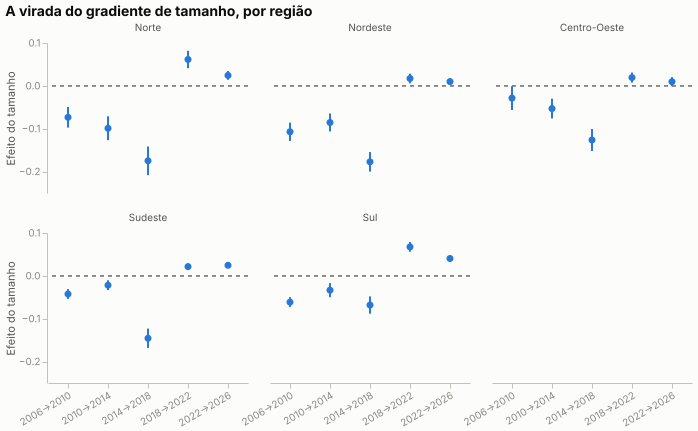

In [3]:
resultados.grafico(
    live,
    "E0_regiao",
    alt.layer(
        zero,
        alt.Chart()
        .mark_rule(strokeWidth=2, color=SERIES[0])
        .encode(
            x=alt.X("transicao:N", title=None, sort=None, axis=alt.Axis(labelAngle=-30)),
            y=alt.Y("ic_inf:Q", title="Efeito do tamanho"),
            y2="ic_sup:Q",
        ),
        alt.Chart()
        .mark_circle(size=50, opacity=1, color=SERIES[0])
        .encode(
            x=alt.X("transicao:N", sort=None),
            y="coef:Q",
            tooltip=[
                alt.Tooltip("regiao:N", title="Região"),
                alt.Tooltip("transicao:N", title="Transição"),
                alt.Tooltip("coef:Q", title="Efeito do tamanho", format="+.3f"),
                alt.Tooltip("ic_inf:Q", title="IC inf.", format="+.3f"),
                alt.Tooltip("ic_sup:Q", title="IC sup.", format="+.3f"),
                alt.Tooltip("amcs:Q", title="AMCs"),
            ],
        ),
        data=por_regiao,
    )
    .properties(width=200, height=150)
    .facet(facet=alt.Facet("regiao:N", sort=list(REGIOES.values()), title=None), columns=3)
    .properties(title="A virada do gradiente de tamanho, por região"),
)

**A virada aparece nas cinco regiões.** Em todas, o efeito do tamanho é negativo de 2006 a
2018, com o pico em 2014→2018 (de −0,07 no Sul a −0,18 no Norte e no Nordeste), e positivo
em 2018→2022 e 2022→2026 (no Centro-Oeste, o IC de 2022→2026 toca o zero). Não é um
fenômeno de uma região. O Sul é a região que mais se move depois de 2018 (+0,068 e +0,040).

## 2 · Sobrevive no confronto direto (2º turno)?

No 1º turno, a fatia "entre os dois maiores" depende de quem mais estava na disputa. De 2010
a 2018, os outros candidatos (Marina, Ciro, Alckmin em 2018…) tinham muito mais voto nas
cidades grandes. Primeiro, o tamanho dessa fragmentação; depois, o mesmo modelo no 2º turno,
em que só há o PT e o adversário. (O 2º turno de 2026 ainda não aconteceu.)

In [4]:
faixas_frag = [10_000, 50_000, 200_000, 1_000_000]
rotulos_frag = ["< 10 mil", "10–50 mil", "50–200 mil", "200 mil–1 mi", "≥ 1 mi"]
fragmentacao = (
    painel.filter(pl.col("turno") == 1)
    .with_columns(
        faixa=pl.col("aptos").bin_intervals(faixas_frag, labels=rotulos_frag).cast(pl.String)
    )
    .group_by("ano", "faixa")
    .agg(outros=100 * pl.col("votos_outros").sum() / pl.col("validos").sum())
    .pivot(on="faixa", index="ano", values="outros")
    .select("ano", *rotulos_frag)
    .sort("ano")
)
for linha in fragmentacao.iter_rows(named=True):
    resultados.metricas(
        live,
        f"E0/outros_pct_validos/{linha['ano']}",
        {resultados.chave(f): linha[f] for f in rotulos_frag},
    )
print("Votos em outros candidatos, % dos válidos, 1º turno, por eleitorado da AMC")
fragmentacao.with_columns(pl.all().exclude("ano").round(1))

Votos em outros candidatos, % dos válidos, 1º turno, por eleitorado da AMC

ano,< 10 mil,10–50 mil,50–200 mil,200 mil–1 mi,≥ 1 mi
i16,f64,f64,f64,f64,f64
2006,5.0,5.9,9.3,13.4,15.7
2010,9.5,12.4,21.4,27.7,30.3
2014,12.4,17.4,26.3,32.7,33.3
2018,19.3,20.6,24.1,27.0,32.0
2022,5.9,6.2,8.1,9.7,11.6
2026,6.0,6.0,8.0,9.1,9.9


In [5]:
turnos = pl.DataFrame(
    [{**gradiente(de, para, turno=1), "turno": "1º turno"} for de, para in TRANSICOES]
    + [{**gradiente(de, para, turno=2), "turno": "2º turno"} for de, para in TRANSICOES[:-1]]
)
for t in (1, 2):
    registra(f"E0/turno{t}", turnos.filter(pl.col("turno") == f"{t}º turno"), tabela=f"E0_turno{t}")
turnos.pivot(on="turno", index="transicao", values="coef").with_columns(
    pl.all().exclude("transicao").round(3)
)

transicao,1º turno,2º turno
str,f64,f64
"""2006→2010""",-0.062,-0.058
"""2010→2014""",-0.046,-0.03
"""2014→2018""",-0.133,-0.081
"""2018→2022""",0.036,0.013
"""2022→2026""",0.025,null


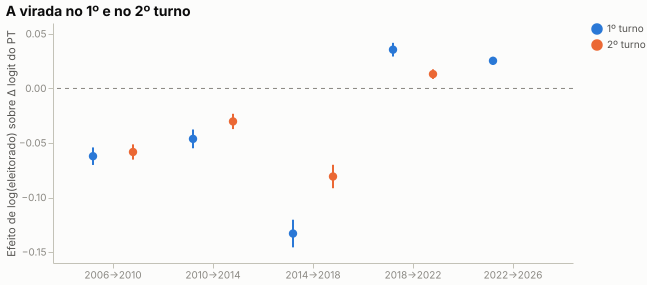

In [6]:
ordem_turnos = ["1º turno", "2º turno"]
cor_turno = alt.Color(
    "turno:N", sort=ordem_turnos, scale=alt.Scale(domain=ordem_turnos, range=SERIES[:2]), title=None
)
base_t = alt.Chart(turnos).encode(
    x=alt.X("transicao:N", title=None, sort=None, axis=alt.Axis(labelAngle=0)),
    xOffset=alt.XOffset("turno:N", sort=ordem_turnos),
    color=cor_turno,
    tooltip=[
        alt.Tooltip("turno:N", title="Turno"),
        alt.Tooltip("transicao:N", title="Transição"),
        alt.Tooltip("coef:Q", title="Efeito do tamanho", format="+.3f"),
        alt.Tooltip("ic_inf:Q", title="IC inf.", format="+.3f"),
        alt.Tooltip("ic_sup:Q", title="IC sup.", format="+.3f"),
    ],
)
resultados.grafico(
    live,
    "E0_turnos",
    (
        zero
        + base_t.mark_rule(strokeWidth=2).encode(
            y=alt.Y("ic_inf:Q", title="Efeito de log(eleitorado) sobre Δ logit do PT"),
            y2="ic_sup:Q",
        )
        + base_t.mark_circle(size=70, opacity=1).encode(y="coef:Q")
    ).properties(width=520, height=240, title="A virada no 1º e no 2º turno"),
)

**A virada sobrevive ao confronto direto, mais fraca.** Entre 2010 e 2018, os outros
candidatos tinham 27–33% dos válidos nas AMCs com mais de 200 mil eleitores, contra 10–19%
nas com menos de 10 mil; em 2022 caem para 6–12%. No 2º turno o sinal muda do mesmo jeito:
−0,081 em 2014→2018 e **+0,013** em 2018→2022 (IC +0,009 a +0,018). Parte do gradiente do
1º turno vem de quem mais disputava nas cidades grandes (Marina, Ciro, Alckmin em 2018), mas
a virada não depende disso.

## 3 · Inversão ou recuperação parcial?

A C5 compara pleitos **vizinhos**. Para saber onde as cidades grandes estão hoje em relação
ao passado, o mesmo modelo com um ponto de partida **fixo**: de 2006 (e de 2014) para cada
pleito seguinte. Se 2018 tivesse invertido de vez a tendência, o efeito acumulado desde 2014
ficaria positivo em 2022 ou 2026.

**Como ler:** cada ponto compara o pleito de partida com o pleito do eixo. Abaixo de zero,
desde o ponto de partida as cidades grandes se afastaram mais do PT que as pequenas.

In [7]:
acumulado = pl.DataFrame(
    [
        {**gradiente(base, para), "partida": f"desde {base}"}
        for base in (2006, 2014)
        for para in ANOS
        if para > base
    ]
)
for base in (2006, 2014):
    registra(
        f"E0/acumulado/desde_{base}",
        acumulado.filter(pl.col("partida") == f"desde {base}"),
        rotulo="para",
        tabela=f"E0_acumulado_desde_{base}",
    )
acumulado.pivot(on="partida", index="para", values="coef").sort("para").with_columns(
    pl.all().exclude("para").round(3)
)

para,desde 2006,desde 2014
i64,f64,f64
2010,-0.062,null
2014,-0.089,null
2018,-0.201,-0.133
2022,-0.105,-0.057
2026,-0.07,-0.026


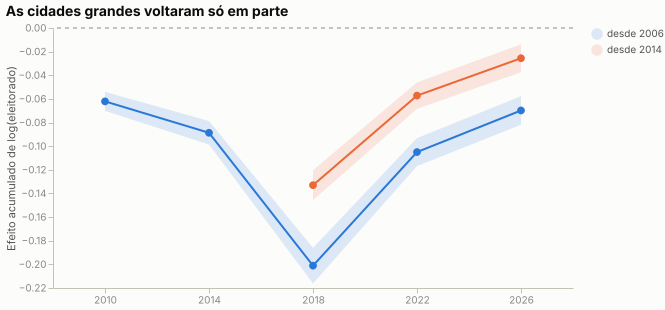

In [8]:
partidas = ["desde 2006", "desde 2014"]
base_a = alt.Chart(acumulado).encode(
    x=alt.X("para:O", title=None, axis=alt.Axis(labelAngle=0)),
    color=alt.Color(
        "partida:N", sort=partidas, scale=alt.Scale(domain=partidas, range=SERIES[:2]), title=None
    ),
    tooltip=[
        alt.Tooltip("transicao:N", title="Comparação"),
        alt.Tooltip("coef:Q", title="Efeito do tamanho", format="+.3f"),
        alt.Tooltip("ic_inf:Q", title="IC inf.", format="+.3f"),
        alt.Tooltip("ic_sup:Q", title="IC sup.", format="+.3f"),
    ],
)
resultados.grafico(
    live,
    "E0_acumulado",
    (
        zero
        + base_a.mark_area(opacity=0.15).encode(
            y=alt.Y("ic_inf:Q", title="Efeito acumulado de log(eleitorado)"), y2="ic_sup:Q"
        )
        + base_a.mark_line(point=alt.OverlayMarkDef(size=60, filled=True)).encode(y="coef:Q")
    ).properties(width=520, height=260, title="As cidades grandes voltaram só em parte"),
)

**Não é uma inversão completa.** Desde 2014, o efeito acumulado é −0,133 em 2018, −0,057 em
2022 e −0,026 em 2026 (IC −0,037 a −0,014): as cidades grandes voltaram ao PT só em parte, e
em 2026 ainda estão mais longe dele, em relação às pequenas, do que em 2014. Desde 2006, o
mesmo desenho (−0,201 no fundo, em 2018; −0,070 em 2026).

Leitura: 2014→2018 foi um **choque** contra o PT, muito maior nas cidades grandes; o que veio
depois é **recuperação parcial** delas somada a um **afastamento novo dos municípios
pequenos**. São dois fenômenos para explicar, não um.

## 4 · É efeito "filhos da terra"?

Candidatos costumam ir melhor no próprio estado, e os estados de origem são grandes e
urbanos: SP (Alckmin, Serra, Haddad), MG (Aécio; Dilma nasceu lá) e RJ (os Bolsonaros). Se a
virada viesse daí, sumiria sem esses três estados.

In [9]:
sem_origem = pl.col("uf").is_in(["SP", "MG", "RJ"]).not_()
filhos = pl.DataFrame(
    [{**gradiente(de, para), "amostra": "Brasil"} for de, para in TRANSICOES]
    + [
        {**gradiente(de, para, filtro=sem_origem), "amostra": "sem SP, MG e RJ"}
        for de, para in TRANSICOES
    ]
)
registra(
    "E0/sem_sp_mg_rj",
    filhos.filter(pl.col("amostra") == "sem SP, MG e RJ"),
    tabela="E0_sem_sp_mg_rj",
)
filhos.pivot(on="amostra", index="transicao", values="coef").with_columns(
    pl.all().exclude("transicao").round(3)
)

transicao,Brasil,"sem SP, MG e RJ"
str,f64,f64
"""2006→2010""",-0.062,-0.074
"""2010→2014""",-0.046,-0.062
"""2014→2018""",-0.133,-0.125
"""2018→2022""",0.036,0.043
"""2022→2026""",0.025,0.026


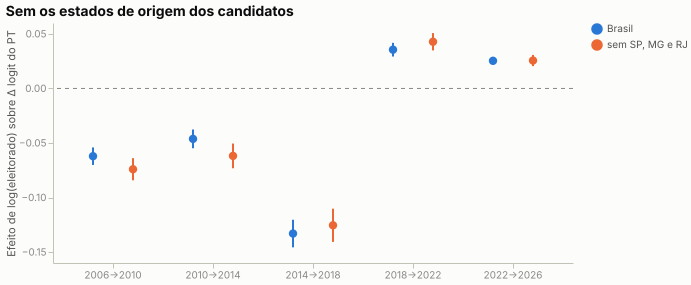

In [10]:
amostras = ["Brasil", "sem SP, MG e RJ"]
base_f = alt.Chart(filhos).encode(
    x=alt.X("transicao:N", title=None, sort=None, axis=alt.Axis(labelAngle=0)),
    xOffset=alt.XOffset("amostra:N", sort=amostras),
    color=alt.Color(
        "amostra:N", sort=amostras, scale=alt.Scale(domain=amostras, range=SERIES[:2]), title=None
    ),
    tooltip=[
        alt.Tooltip("amostra:N", title="Amostra"),
        alt.Tooltip("transicao:N", title="Transição"),
        alt.Tooltip("coef:Q", title="Efeito do tamanho", format="+.3f"),
        alt.Tooltip("ic_inf:Q", title="IC inf.", format="+.3f"),
        alt.Tooltip("ic_sup:Q", title="IC sup.", format="+.3f"),
        alt.Tooltip("amcs:Q", title="AMCs"),
    ],
)
resultados.grafico(
    live,
    "E0_sem_sp_mg_rj",
    (
        zero
        + base_f.mark_rule(strokeWidth=2).encode(
            y=alt.Y("ic_inf:Q", title="Efeito de log(eleitorado) sobre Δ logit do PT"),
            y2="ic_sup:Q",
        )
        + base_f.mark_circle(size=70, opacity=1).encode(y="coef:Q")
    ).properties(width=520, height=240, title="Sem os estados de origem dos candidatos"),
)

**Não é efeito "filhos da terra".** Sem SP, MG e RJ os coeficientes quase não mudam
(2014→2018: −0,125 contra −0,133 no Brasil; 2018→2022: +0,043 contra +0,036).

## 5 · Comparecimento ou mudança de voto?

A mesma decomposição da A6 (`04_decomposicao.ipynb`): os votos do PT numa AMC são
eleitorado × comparecimento × válidos/comparecimento × fatia do PT, e a variação se divide
exatamente entre os quatro fatores. Aqui, somada por faixa de eleitorado e expressa em % dos
votos que o PT tinha na faixa no pleito de partida. Comparecimento e brancos/nulos vão
juntos, como **mobilização**.

In [11]:
faixas = [5_000, 10_000, 20_000, 50_000, 100_000, 500_000]
rotulos = [
    "< 5 mil",
    "5–10 mil",
    "10–20 mil",
    "20–50 mil",
    "50–100 mil",
    "100–500 mil",
    "≥ 500 mil",
]


def votos_pt(ano, sufixo):
    return pleito(ano, 1).select(
        "amc_id",
        *(pl.col(c).alias(f"{c}_{sufixo}") for c in ("aptos", "comparecimento", "validos")),
        pl.col("votos_pt").alias(f"votos_{sufixo}"),
    )


componentes = {
    "Eleitorado": pl.col("c_eleitorado"),
    "Mobilização": pl.col("c_comparecimento") + pl.col("c_validos"),
    "Fatia do PT": pl.col("c_fatia"),
}
linhas = []
for de, para in TRANSICOES:
    dec = decompoe_votos(votos_pt(de, "de").join(votos_pt(para, "para"), on="amc_id"))
    soma = (
        dec.with_columns(
            faixa=pl.col("aptos_de").bin_intervals(faixas, labels=rotulos).cast(pl.String),
            **{nome: expr for nome, expr in componentes.items()},
        )
        .group_by("faixa")
        .agg(pl.col("votos_de", *componentes).sum())
    )
    for r in soma.iter_rows(named=True):
        for nome in componentes:
            linhas.append(
                {
                    "transicao": f"{de}→{para}",
                    "faixa": r["faixa"],
                    "componente": nome,
                    "pct": 100 * r[nome] / r["votos_de"],
                }
            )
decomp = pl.DataFrame(linhas)
decomp.filter(pl.col("componente") != "Eleitorado").pivot(
    on="faixa", index=["transicao", "componente"], values="pct"
).select("transicao", "componente", *rotulos).with_columns(pl.col(rotulos).round(1))

transicao,componente,< 5 mil,5–10 mil,10–20 mil,20–50 mil,50–100 mil,100–500 mil,≥ 500 mil
str,str,f64,f64,f64,f64,f64,f64,f64
"""2006→2010""","""Mobilização""",-2.6,-2.3,-2.3,-2.1,-1.9,-1.8,-2.2
"""2006→2010""","""Fatia do PT""",12.8,8.6,4.4,1.0,-7.1,-11.1,-10.5
"""2010→2014""","""Mobilização""",0.0,0.4,0.7,0.0,-1.5,-3.3,-4.4
"""2010→2014""","""Fatia do PT""",-5.9,-3.8,-5.1,-7.1,-12.2,-16.6,-21.8
"""2014→2018""","""Mobilização""",-0.1,0.9,0.9,1.1,0.1,-0.4,0.3
"""2014→2018""","""Fatia do PT""",-21.4,-19.1,-19.1,-24.6,-35.8,-41.3,-38.7
"""2018→2022""","""Mobilização""",4.0,4.7,5.4,5.3,5.5,5.9,6.5
"""2018→2022""","""Fatia do PT""",31.1,28.5,29.5,40.4,71.9,107.3,136.1
"""2022→2026""","""Mobilização""",-0.9,0.8,1.5,1.2,-0.1,-1.4,-2.1


**Como ler:** um painel por transição; cada barra é quanto um componente somou (direita) ou
tirou (esquerda) dos votos do PT, em % dos votos que o PT tinha na faixa. "Fatia do PT" é
mudança de voto entre os válidos; "mobilização", gente que deixou de votar ou anulou.

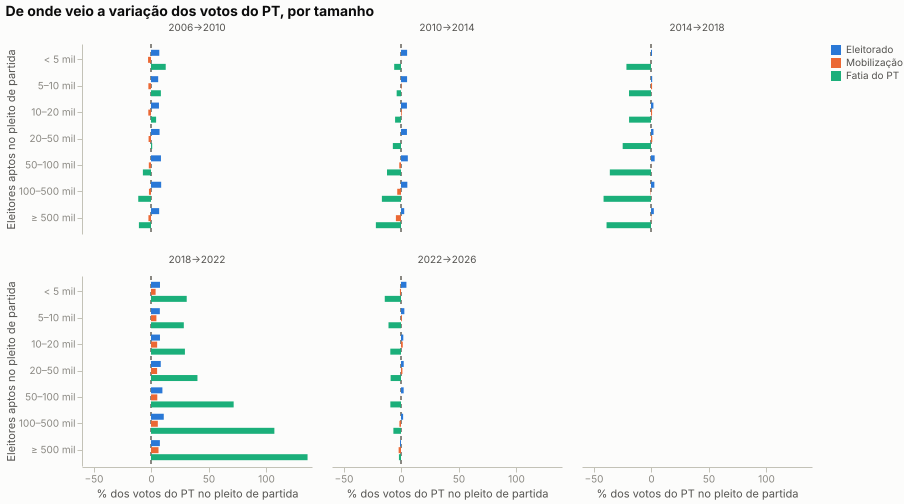

In [12]:
ordem_comp = list(componentes)
resultados.grafico(
    live,
    "E0_decomposicao",
    alt.layer(
        alt.Chart().mark_rule(color=TINTA["apagada"], strokeDash=[4, 4]).encode(x=alt.datum(0)),
        alt.Chart()
        .mark_bar(size=6)
        .encode(
            y=alt.Y("faixa:N", sort=rotulos, title="Eleitores aptos no pleito de partida"),
            yOffset=alt.YOffset("componente:N", sort=ordem_comp),
            x=alt.X("pct:Q", title="% dos votos do PT no pleito de partida"),
            color=alt.Color(
                "componente:N",
                sort=ordem_comp,
                scale=alt.Scale(domain=ordem_comp, range=SERIES[:3]),
                title=None,
            ),
            tooltip=[
                alt.Tooltip("transicao:N", title="Transição"),
                alt.Tooltip("faixa:N", title="Faixa"),
                alt.Tooltip("componente:N", title="Componente"),
                alt.Tooltip("pct:Q", title="% dos votos do PT", format="+.1f"),
            ],
        ),
        data=decomp,
    )
    .properties(width=230, height=190)
    .facet(
        facet=alt.Facet("transicao:N", sort=[f"{a}→{b}" for a, b in TRANSICOES], title=None),
        columns=3,
    )
    .properties(title="De onde veio a variação dos votos do PT, por tamanho"),
)

**Foi mudança de voto, não de comparecimento.** Em todas as transições a mobilização mexe
pouco e quase por igual entre as faixas; o gradiente de tamanho está na fatia do PT.

- **2014→2018:** a fatia tirou 21% dos votos do PT nas AMCs com menos de 5 mil eleitores e
  39–41% nas com mais de 100 mil; a mobilização ficou entre −0,4% e +1,1%.
- **2018→2022:** a mobilização ajudou o PT um pouco mais nas grandes (+6,5% contra +4,0%),
  pouco perto da fatia. Os +136% nas maiores refletem a base baixa de Haddad nas cidades
  grandes.
- **2022→2026:** o desenho de 2014→2018 ao contrário: fatia −14% nas menores, −2% nas maiores.

Mesmo limite da A6: é uma decomposição ecológica (troca de eleitores dentro do município
aparece como "fatia").

## 6 · O mapa congelou?

Correlação, entre AMCs, do voto de cada lado (% dos válidos) num pleito com o do pleito
anterior. Perto de 1, o mapa se repete: cada lugar vota como votou antes, mudando só o nível.
Inclui o adversário: Bolsonaro em 2018 herdou o mapa do PSDB ou desenhou outro?

**Como ler:** um painel por turno; vermelho é o PT, azul o adversário. No 2º turno as duas
linhas coincidem (com só dois candidatos, uma fatia é o complemento da outra).

In [13]:
LADOS = {"pt_validos": "PT", "adv_validos": "Adversário"}
linhas = []
for turno in (1, 2):
    anos_t = [a for a in ANOS if pleito(a, turno).height]
    for de, para in zip(anos_t[:-1], anos_t[1:], strict=True):
        d = (
            pleito(de, turno)
            .select("amc_id", *LADOS)
            .join(pleito(para, turno).select("amc_id", *LADOS), on="amc_id", suffix="_para")
        )
        for col, lado in LADOS.items():
            correlacao = float(np.corrcoef(d[col], d[f"{col}_para"])[0, 1])
            resultados.metrica(
                live,
                f"E0/congelamento/turno{turno}/{de}_{para}/{resultados.chave(lado)}",
                correlacao,
            )
            linhas.append(
                {
                    "turno": f"{turno}º turno",
                    "transicao": f"{de}→{para}",
                    "lado": lado,
                    "correlacao": correlacao,
                }
            )
congelamento = pl.DataFrame(linhas)
congelamento.pivot(on=["turno", "lado"], index="transicao", values="correlacao").with_columns(
    pl.all().exclude("transicao").round(3)
)

transicao,"{""1º turno"",""PT""}","{""1º turno"",""Adversário""}","{""2º turno"",""PT""}","{""2º turno"",""Adversário""}"
str,f64,f64,f64,f64
"""2006→2010""",0.838,0.887,0.885,0.885
"""2010→2014""",0.892,0.853,0.893,0.893
"""2014→2018""",0.889,0.874,0.934,0.934
"""2018→2022""",0.92,0.975,0.975,0.975
"""2022→2026""",0.985,0.986,null,null


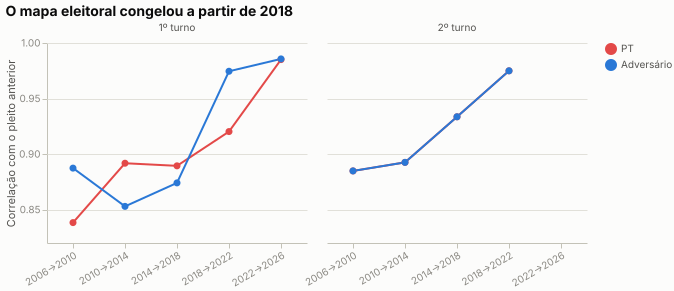

In [14]:
lados = list(LADOS.values())
resultados.grafico(
    live,
    "E0_congelamento",
    alt.Chart(congelamento)
    .mark_line(point=alt.OverlayMarkDef(size=50, filled=True))
    .encode(
        x=alt.X("transicao:N", title=None, sort=None, axis=alt.Axis(labelAngle=-30)),
        y=alt.Y(
            "correlacao:Q", title="Correlação com o pleito anterior", scale=alt.Scale(zero=False)
        ),
        color=alt.Color(
            "lado:N",
            sort=lados,
            scale=alt.Scale(domain=lados, range=[DIVERGENTE["pt"], DIVERGENTE["adversario"]]),
            title=None,
        ),
        tooltip=[
            alt.Tooltip("turno:N", title="Turno"),
            alt.Tooltip("transicao:N", title="Transição"),
            alt.Tooltip("lado:N", title="Lado"),
            alt.Tooltip("correlacao:Q", title="Correlação", format=".3f"),
        ],
    )
    .properties(width=260, height=200)
    .facet(column=alt.Column("turno:N", title=None))
    .properties(title="O mapa eleitoral congelou a partir de 2018"),
)

**O mapa congelou, e no 2º turno isso começa antes de 2018.**

- **Bolsonaro herdou o mapa do PSDB.** No 1º turno, a correlação do adversário entre Aécio
  (2014) e Bolsonaro (2018) é 0,874, igual às trocas anteriores (0,85–0,89). Não houve um
  mapa novo em 2018.
- **De 2018 em diante, cada lugar vota como votou antes:** 0,975 e 0,986 no adversário;
  0,920 e 0,985 no PT.
- **No 2º turno** (as duas linhas coincidem, porque só há dois candidatos), a estabilidade
  sobe já em 2014→2018 (0,934, contra 0,885–0,893 antes) e chega a 0,975 em 2018→2022. O
  molde do mapa polarizado é o 2º turno de 2014 (Dilma × Aécio).

## O que fica para a série E

- **O que a virada é:** nacional (as cinco regiões), presente no 2º turno, sem relação com os
  estados de origem dos candidatos e feita de mudança de voto, não de comparecimento.
- **O que ela não é:** uma inversão simples. São dois fenômenos: **(a)** o choque contra o PT
  em 2014→2018, muito maior nas cidades grandes, que só voltou em parte; **(b)** desde 2018,
  o afastamento dos municípios pequenos, que continua em 2026. Junto, o mapa congelou, com
  o molde já visível no 2º turno de 2014.
- **O que a uniformidade diz sobre as causas:** pouco. Uma quebra igual no país todo é o que
  qualquer causa nacional produz (candidatos, recessão, Lava Jato, campanha digital, igrejas,
  financiamento). O que pode distinguir as causas é a **pegada geográfica e temporal** de
  cada canal. É o que E1–E5 testam, cada uma com placebo nas transições anteriores a
  2014→2018.
- **Restrições que qualquer explicação precisa respeitar:** Bolsonaro herdou o mapa
  antipetista do PSDB, então (a) é sobre por que esse antipetismo cresceu tanto nas cidades
  grandes; e (b) começa depois de 2018, então não se explica por algo que já estava lá
  antes.

In [15]:
live.end()